# Exercise - Simple Linear Regression



In this notebook you can check your understanding of linear regression and implement a linear regression model with scikit-learn by yourself. 




## Learning Objectives

At the end of this notebook, you should be able to: 
- Describe the relationship between two variables.
- Train a linear regression model with scikit-learn.
- Interpret the $R^2$ of a linear regression model.

## Question 1 



The scatter plots below show the relationship between height, diameter, and volume of timber in 31 felled black cherry trees. The diameter of the tree is measured 4.5 feet above the ground.  

<img src="assets/lin_reg_ex_1.png" width="600">  

**(a) Describe the relationship between volume and height of these trees.**

**(b) Describe the relationship between volume and diameter of these trees.**

**(c) Suppose you measured the height and diameter of another black cherry tree. Which of these variables would be better for predicting the wood volume of this tree using a simple linear regression model? Explain your reasoning.**

## Question 2 

The file `utils.csv` in your data folder contains information about the average utility bills for homes of a particular size and the average monthly temperature.  

**(a) Load the data:**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

In [2]:
df = pd.read_csv("data/utils.csv")
df


,Month,Average Bill,Average Monthly Temperature
0,Jan,148.5,38
1,Feb,136.5,45
2,Mar,117.0,49
3,Apr,91.5,57
4,May,82.5,69
5,Jun,94.5,78
6,Jul,120.0,84
7,Aug,142.5,89
8,Sep,97.5,79
9,Oct,84.0,64


**(b) Make a scatter plot of the data average bill vs average monthly temperature. Which variable would make the most sense as the response variable?**

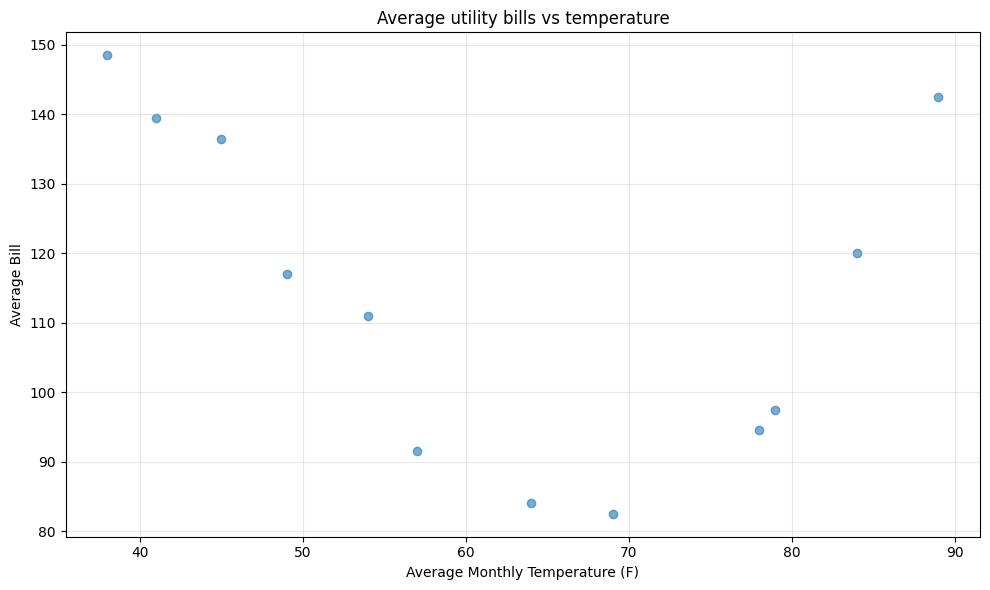

In [3]:
plt.figure(figsize=(10,6))
plt.scatter(df["Average Monthly Temperature"], df["Average Bill"], alpha=0.6)
plt.xlabel("Average Monthly Temperature (F)")
plt.ylabel("Average Bill")
plt.title("Average utility bills vs temperature")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**(c) Have a look at the plot above. How would you describe the relationship between the variables?** 

**(d) Train a simple linear regression model using scikit-learn**

In [6]:
X = df[["Average Monthly Temperature"]]
y = df["Average Bill"]

lin_reg = LinearRegression()
lin_reg.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.48]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Average Monthly Temperature']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,143.6
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


**(e) Calculate and interpret the value of $R^2$.**  

In [ ]:
from sklearn.metrics import r2_score

In [13]:
# calculate R²:
r2 = lin_reg.score(X, y)
print(f"R²_value: {r2:.3f}")

y_pred = lin_reg.predict(X)
r2_alter = r2_score(y, y_pred)
print(f"R²_alter: {r2_alter:.3f}")

R²_value: 0.124
R²_alter: 0.124


**(f) Print the intercept and slope/coefficient and interpret them in terms a home owner would understand.**

In [20]:
intercept = lin_reg.intercept_
coef = lin_reg.coef_
print(f"intercpt: {round(intercept, 3)}, slope: {coef}")

intercpt: 143.623, slope: [-0.47988442]


**(g) Use your fitted model to estimate the average utility bill if the average monthly temperature is 120 degrees Fahrenheit. Do you think that your answer is reasonable? Why or why not?** 

In [27]:
avg_month_temp = 120
new_bill = lin_reg.predict([[avg_month_temp]])[0]
print(f"Estimated average utility bill for average temperature of 120:\n{new_bill}")

Estimated average utility bill for average temperature of 120:
86.03667481662592


/Users/maryamsajedi/Desktop/Materials/ds-linear-regression-en/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
